<a href="https://colab.research.google.com/github/Anton-maxi/pattern-recognition-practice/blob/model-comparison/classification-mini-project/notebooks/PR04_Zboryk_Anton.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практичні роботи 4–7. Мініпроєкт «Порівняння класичних моделей класифікації»

**Курс:** Розпізнавання образів та класичне машинне навчання  
**Студент:** Зборик Антон, ІН-42/2  
**Набір даних:** Heart Disease (UCI), файл `heart_disease.csv`

## Постановка задачі

**Об'єкт дослідження:** пацієнт, описаний клінічними характеристиками.

**Ознаки (13):** age, sex, cp, trestbps, chol, fbs, restecg, thalach, exang, oldpeak, slope, ca, thal.

**Цільова змінна:** `target`.

**Кількість класів:** 2 (бінарна класифікація з навчанням за розміченими даними).

**Позитивний клас:** 1 (ознаки серцевого захворювання наявні). Клас 0 означає, що ознак захворювання немає.

**Практична мета:** за характеристиками пацієнта визначити, чи належить він до класу з наявністю ознак серцевого захворювання, і порівняти класичні моделі класифікації за однаковою схемою стратифікованої крос-валідації.

**Основна метрика:** F1 для позитивного класу. Додаткові метрики: recall позитивного класу (важливо не пропустити хворого) та ROC AUC. Метрику обрано до початку експериментів і далі не змінюється.

**Застереження:** результати навчального мініпроєкту не є медичним діагнозом і не повинні використовуватися для клінічних рішень.

In [94]:
import os
import numpy as np
import pandas as pd

from google.colab import drive
drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/3_course/Image_Recognition_and_Classical_Machine_Learning"
DATA_PATH = os.path.join(PROJECT_DIR, "data", "heart_disease.csv")
MODELS_DIR = os.path.join(PROJECT_DIR, "models")
REPORTS_DIR = os.path.join(PROJECT_DIR, "reports")

os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(REPORTS_DIR, exist_ok=True)

print("PROJECT_DIR:", PROJECT_DIR)
print("Файл даних існує:", os.path.exists(DATA_PATH))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PROJECT_DIR: /content/drive/MyDrive/3_course/Image_Recognition_and_Classical_Machine_Learning
Файл даних існує: True


In [95]:
df = pd.read_csv(DATA_PATH)

print("Розмір таблиці:", df.shape)
display(df.head())
print()
print(df.dtypes)

Розмір таблиці: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0



age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
target        int64
dtype: object


In [96]:
print("Пропуски по стовпцях:")
print(df.isna().sum())
print("Усього пропусків:", df.isna().sum().sum())
print()
print("Розподіл класів (кількість):")
print(df["target"].value_counts())
print()
print("Розподіл класів (частка):")
print(df["target"].value_counts(normalize=True).round(4))
print()
print("Унікальні значення target:", sorted(df["target"].unique()))

Пропуски по стовпцях:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64
Усього пропусків: 6

Розподіл класів (кількість):
target
0    164
1    139
Name: count, dtype: int64

Розподіл класів (частка):
target
0    0.5413
1    0.4587
Name: proportion, dtype: float64

Унікальні значення target: [np.int64(0), np.int64(1)]


In [97]:
numeric_columns = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_columns = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
target_column = "target"

print("Числові ознаки:", numeric_columns)
print("Категоріальні ознаки:", categorical_columns)
print("Цільова змінна:", target_column)

Числові ознаки: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Категоріальні ознаки: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
Цільова змінна: target


## Первинний аудит даних

| Характеристика | Значення |
|---|---|
| Кількість об'єктів | 303 |
| Кількість вхідних ознак | 13 |
| Числові ознаки | age, trestbps, chol, thalach, oldpeak (5) |
| Категоріальні ознаки | sex, cp, fbs, restecg, exang, slope, ca, thal (8) |
| Кількість пропусків | 6 (ca: 4, thal: 2) |
| Кількість класів | 2 |
| Позитивний клас | 1 |

**Розподіл класів:** клас 0 – 164 об'єкти (54,13%), клас 1 – 139 об'єктів (45,87%). Класи майже збалансовані.

**Висновок:** дані придатні для побудови моделей. Значення `target` лише 0 і 1. Пропуски є тільки в ознаках `ca` і `thal`, тому їх заповнення виконуватиметься всередині Pipeline (мода, обчислена лише на навчальній частині). Частина категоріальних ознак (наприклад, `cp`) збережена числовими кодами, тому вони обробляються як категоріальні, а не як кількісні.

In [98]:
from sklearn.model_selection import train_test_split, StratifiedKFold

X = df.drop(columns=[target_column])
y = df[target_column]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)
print()
print("Клас 0 і 1 у y_train:")
print(y_train.value_counts())
print("Клас 0 і 1 у y_test:")
print(y_test.value_counts())

X_train: (242, 13) | X_test: (61, 13)
y_train: (242,) | y_test: (61,)

Клас 0 і 1 у y_train:
target
0    131
1    111
Name: count, dtype: int64
Клас 0 і 1 у y_test:
target
0    33
1    28
Name: count, dtype: int64


In [99]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print(cv)

StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


In [100]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

model_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

In [101]:
numeric_pipeline_noscale = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", "passthrough")
])

preprocessor_noscale = ColumnTransformer([
    ("num", numeric_pipeline_noscale, numeric_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

model_pipeline_noscale = Pipeline([
    ("preprocessor", preprocessor_noscale),
    ("classifier", LogisticRegression(max_iter=2000))
])

In [102]:
preprocessor.fit(X_train)
X_train_prepared = preprocessor.transform(X_train)

print("Форма X_train після препроцесингу:", X_train_prepared.shape)
print("Пропусків після препроцесингу:", np.isnan(X_train_prepared).sum())
print()
print(preprocessor.get_feature_names_out())

Форма X_train після препроцесингу: (242, 28)
Пропусків після препроцесингу: 0

['num__age' 'num__trestbps' 'num__chol' 'num__thalach' 'num__oldpeak'
 'cat__sex_0.0' 'cat__sex_1.0' 'cat__cp_1.0' 'cat__cp_2.0' 'cat__cp_3.0'
 'cat__cp_4.0' 'cat__fbs_0.0' 'cat__fbs_1.0' 'cat__restecg_0.0'
 'cat__restecg_1.0' 'cat__restecg_2.0' 'cat__exang_0.0' 'cat__exang_1.0'
 'cat__slope_1.0' 'cat__slope_2.0' 'cat__slope_3.0' 'cat__ca_0.0'
 'cat__ca_1.0' 'cat__ca_2.0' 'cat__ca_3.0' 'cat__thal_3.0' 'cat__thal_6.0'
 'cat__thal_7.0']


In [103]:
from sklearn.model_selection import cross_validate
import warnings
scoring={"F1":"f1",
         "ROC_AUC":"roc_auc",
         "RECALL":"recall"}

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    res = cross_validate(model_pipeline, X_train, y_train, cv=cv, scoring=scoring)
    model_pipeline.fit(X_train, y_train)
    clf = model_pipeline.named_steps["classifier"]

print("Результат cross_validate:", res)
print("CV F1, середнє:", res["test_F1"].mean())
print("CV F1, std:", res["test_F1"].std())
print("CV ROC AUC, середнє:", res["test_ROC_AUC"].mean())
print("CV ROC AUC, std:", res["test_ROC_AUC"].std())
print("CV Recall, середнє:", res["test_RECALL"].mean())

print("Ітерацій оптимізатора після fit на train:", clf.n_iter_[0])

print("Кількість попереджень:", len(caught))

Результат cross_validate: {'fit_time': array([0.0290029 , 0.02850056, 0.15007472, 0.0182209 , 0.02957582]), 'score_time': array([0.02356982, 0.05030298, 0.04895401, 0.01968002, 0.03817916]), 'test_F1': array([0.82608696, 0.82051282, 0.82051282, 0.81818182, 0.8372093 ]), 'test_ROC_AUC': array([0.9180602 , 0.90909091, 0.88986014, 0.91433566, 0.88111888]), 'test_RECALL': array([0.82608696, 0.72727273, 0.72727273, 0.81818182, 0.81818182])}
CV F1, середнє: 0.8245007436109558
CV F1, std: 0.006866722884370779
CV ROC AUC, середнє: 0.9024931590148981
CV ROC AUC, std: 0.01443995119614911
CV Recall, середнє: 0.783399209486166
Ітерацій оптимізатора після fit на train: 18
Кількість попереджень: 6


In [104]:
print("Попередження, які зловили (caught):")
for elm in caught:
    print("Тип:", elm.category.__name__)
    print("Текст:", str(elm.message)[:120])

Попередження, які зловили (caught):
Тип: DeprecationWarning
Текст: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.
Тип: DeprecationWarning
Текст: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.
Тип: DeprecationWarning
Текст: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.
Тип: DeprecationWarning
Текст: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.
Тип: DeprecationWarning
Текст: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.
Тип: DeprecationWarning
Текст: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.


In [105]:
import pandas as pd
rows=[]
for name, pipe in [("Зі StandardScaler", model_pipeline),("Без масштабування", model_pipeline_noscale)]:
  with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    pipe.fit(X_train, y_train)
  clf = pipe.named_steps["classifier"]
  countWarning = 0
  for elm in caught:
    if elm.category.__name__ == "ConvergenceWarning":
      countWarning +=1
  rows.append({"Pipeline": name, "CV F1": res["test_F1"].mean(), "F1 std": res["test_F1"].std(), "ROC AUC середнє": res["test_ROC_AUC"].mean(), "ROC AUC std": res["test_ROC_AUC"].std(), "Recall середнє": res["test_RECALL"].mean(), "Ітерацій": clf.n_iter_[0], "ConvergenceWarning": countWarning})
df=pd.DataFrame(rows)
display(df.round(4))

,Pipeline,CV F1,F1 std,ROC AUC середнє,ROC AUC std,Recall середнє,Ітерацій,ConvergenceWarning
0,Зі StandardScaler,0.8245,0.0069,0.9025,0.0144,0.7834,18,0
1,Без масштабування,0.8245,0.0069,0.8997,0.0157,0.7834,1238,0


### Вплив масштабування на логістичну регресію

Порівняння виконано лише за 5-кратною StratifiedKFold на навчальній вибірці.

| Pipeline | CV F1 | F1 std | CV ROC AUC | ROC AUC std | CV Recall | Ітерацій | ConvergenceWarning |
|---|---:|---:|---:|---:|---:|---:|---:|
| Зі StandardScaler | 0,8245 | 0,0069 | 0,9025 | 0,0144 | 0,7834 | 18 | 0 |
| Без масштабування | 0,8245 | 0,0069 | 0,8997 | 0,0157 | 0,7834 | 1238 | 0 |

**Висновок:** за якістю прогнозів масштабування майже нічого не змінило: CV F1 і CV Recall збіглися, CV ROC AUC трохи вищий зі стандартизацією (0,9025 проти 0,8997), а розкид між фолдами трохи менший (0,0144 проти 0,0157). Основна різниця в збіжності: зі стандартизацією оптимізатору вистачило 18 ітерацій, а без неї знадобилося 1238, бо ознаки мають дуже різний числовий діапазон (наприклад, `chol` у сотнях, `oldpeak` в одиницях). Попереджень про збіжність (ConvergenceWarning) в обох варіантах не було, оскільки 1238 менше за ліміт max_iter=2000. Для подальшої роботи обираємо варіант зі StandardScaler: якість не гірша, навчання стабільніше й швидше, а коефіцієнти числових ознак можна коректніше порівнювати між собою.

In [106]:
from sklearn.model_selection import GridSearchCV

L1={"classifier__penalty": ["l1"],
    "classifier__solver": ["liblinear"],
    "classifier__C": [0.01, 0.1, 1, 10, 100]}
L2={"classifier__penalty": ["l2"],
    "classifier__solver": ["liblinear"],
    "classifier__C": [0.01, 0.1, 1, 10, 100]}
param_grid=[L1,L2]
grid= GridSearchCV(model_pipeline, param_grid, scoring="f1", cv=cv)
grid.fit(X_train, y_train)
print("Найкращі параметри за GridSearchCV:", grid.best_params_)
print("Найкращий CV F1:", grid.best_score_)
df=pd.DataFrame(grid.cv_results_)
df=df[["param_classifier__penalty","param_classifier__C", "mean_test_score", "std_test_score"]]
print()
print("Усі конфігурації, відсортовані за середнім CV F1:")
display(df.sort_values("mean_test_score", ascending=False))

Найкращі параметри за GridSearchCV: {'classifier__C': 100, 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'}
Найкращий CV F1: 0.8362956154058278

Усі конфігурації, відсортовані за середнім CV F1:


,param_classifier__penalty,param_classifier__C,mean_test_score,std_test_score
9,l2,100.00,0.836296,0.012718
4,l1,100.00,0.836296,0.012718
8,l2,10.00,0.836296,0.012718
3,l1,10.00,0.832149,0.010811
7,l2,1.00,0.824501,0.006867
6,l2,0.10,0.814050,0.029901
2,l1,1.00,0.812256,0.017305
1,l1,0.10,0.792641,0.030558
5,l2,0.01,0.765777,0.017125
0,l1,0.01,0.000000,0.000000


### Вибір найкращої конфігурації логістичної регресії

Три конфігурації мають однаковий CV F1 (0,8363) і однаковий розкид між фолдами (0,0127): L2 з C = 10, L2 з C = 100 та L1 з C = 100. Тому `best_params_` з GridSearchCV не є змістовним вибором: від запуску до запуску він міг показувати різні з цих трьох.

Правило вибору (зафіксовано до подальшої роботи): за однакового CV F1 обираємо конфігурацію з сильнішою регуляризацією, тобто з меншим C, бо вона простіша й менш схильна до перенавчання.

**Обрано: LogisticRegression, penalty = "l2", C = 10, solver = "liblinear" (зі StandardScaler).** CV F1 = 0,8363, std = 0,0127.

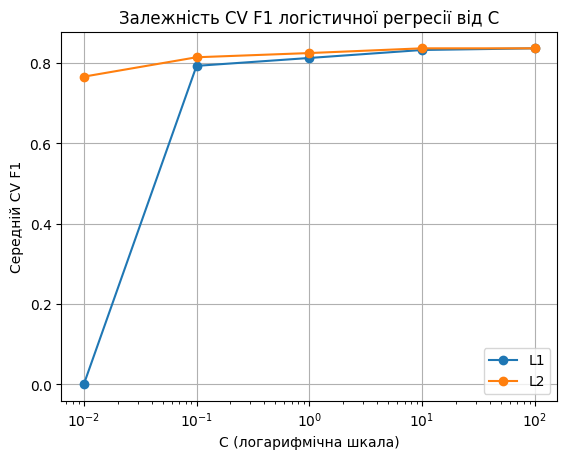

In [107]:
import matplotlib.pyplot as plt

df_l1=df[df["param_classifier__penalty"] == "l1"]
df_l2=df[df["param_classifier__penalty"] == "l2"]
plt.plot(df_l1["param_classifier__C"], df_l1["mean_test_score"], marker="o", label="L1")
plt.plot(df_l2["param_classifier__C"], df_l2["mean_test_score"], marker="o", label="L2")
plt.xscale("log")
plt.xlabel("C (логарифмічна шкала)")
plt.ylabel("Середній CV F1")
plt.title("Залежність CV F1 логістичної регресії від C")
plt.legend()
plt.grid(True)
plt.show()

### Вплив C та типу регуляризації на CV F1

- **Мале C (сильна регуляризація) шкодить.** При C = 0,01 CV F1 для L2 лише 0,7658, а для L1 дорівнює 0: штраф настільки сильний, що модель не передбачає позитивний клас.
- **Зі зростанням C якість зростає й виходить на плато.** Для L2 CV F1 піднімається від 0,7658 (C = 0,01) до 0,8141, 0,8245, 0,8363 (C = 10) і лишається 0,8363 при C = 100. Для L1 те саме: 0,7926, 0,8123, 0,8321, 0,8363 (C = 100).
- **L2 стабільніший при малих C**, L1 при C від 10 майже не відрізняється від L2.
- Три конфігурації (L2 з C = 10, L2 з C = 100, L1 з C = 100) мають однаковий CV F1 = 0,8363. За правилом «за однакового F1 беремо сильнішу регуляризацію» обрано **L2, C = 10**.

In [108]:
best_lr = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(penalty="l2", C=10, solver="liblinear", max_iter=2000))
])
best_lr.fit(X_train, y_train)
coef_df=pd.DataFrame({"feature": best_lr.named_steps["preprocessor"].get_feature_names_out(), "coef": best_lr.named_steps["classifier"].coef_[0]})
coef_df["abs_coef"]=np.abs(coef_df["coef"])

print("П'ять найбільших за модулем коефіцієнтів (L2, C=10):")
display(coef_df.sort_values("abs_coef", ascending=False).head(5).round(4))

П'ять найбільших за модулем коефіцієнтів (L2, C=10):


,feature,coef,abs_coef
21,cat__ca_0.0,-1.9262,1.9262
10,cat__cp_4.0,1.1886,1.1886
27,cat__thal_7.0,0.9779,0.9779
7,cat__cp_1.0,-0.8921,0.8921
5,cat__sex_0.0,-0.8802,0.8802


### Найбільші за модулем коефіцієнти (L2, C = 10)

| Ознака | Коефіцієнт | Вплив на log-odds класу 1 |
|---|---:|---|
| ca = 0 | -1,9262 | знижує |
| cp = 4 | 1,1886 | підвищує |
| thal = 7 | 0,9779 | підвищує |
| cp = 1 | -0,8921 | знижує |
| sex = 0 | -0,8802 | знижує |

Додатний коефіцієнт збільшує log-odds позитивного класу (наявність ознак захворювання) за інших рівних умов, від'ємний зменшує. Усі п'ять найбільших коефіцієнтів належать категоріальним ознакам, закодованим one-hot (кожен така колонка дорівнює 0 або 1), жодна числова ознака в п'ятірку не потрапила. Тому ці величини не можна напряму порівнювати з коефіцієнтами числових ознак: для числових (після StandardScaler) коефіцієнт показує зміну log-odds на одне стандартне відхилення ознаки, а для one-hot на перехід від 0 до 1. Найсильніше на результат впливає `ca = 0` (відсутність помітних судин знижує оцінку ризику), далі `cp = 4` і `thal = 7`. Коефіцієнти описують зв'язок у даних, а не причинно-наслідковий чи медичний вплив: наприклад, від'ємний коефіцієнт у `cp = 1` не означає, що типова стенокардія захищає від хвороби.

### Висновок за практичною роботою 4

- **Масштабування.** CV F1 (0,8245) і CV Recall (0,7834) зі StandardScaler і без нього збіглися, CV ROC AUC трохи вищий зі стандартизацією (0,9025 проти 0,8997), розкид між фолдами теж трохи менший (0,0144 проти 0,0157). Головна різниця в збіжності: зі стандартизацією оптимізатору вистачило 18 ітерацій, без неї знадобилося 1238. Попереджень про збіжність не було в обох випадках. Для подальшої роботи обрано варіант зі StandardScaler.
- **Регуляризація.** Для C = 0,01 CV F1 найнижчий: 0,7658 для L2 і 0 для L1 (штраф настільки сильний, що модель перестала передбачати позитивний клас). L2 стабільніший за L1 при малих C, а при C від 10 обидва штрафи дають майже однаковий результат.
- **Значення C.** З ростом C якість зростає й виходить на плато: для L2 від 0,7658 (C = 0,01) до 0,8363 (C = 10), далі без змін. Три конфігурації (L2 з C = 10, L2 з C = 100, L1 з C = 100) мали однаковий CV F1 = 0,8363. Обрано L2 з C = 10 за правилом «за однакового F1 беремо сильнішу регуляризацію», CV F1 = 0,8363, std = 0,0127.
- **Коефіцієнти.** Найбільший вплив мають `ca = 0` (−1,9262), `cp = 4` (1,1886) і `thal = 7` (0,9779). Це зв'язок у даних, а не доказ причинності.
- Тестову вибірку на цьому етапі не використовували.

## Додаткове завдання: детальний аналіз коефіцієнтів логістичної регресії

Для обраної за крос-валідацією моделі (L2, C = 10, зі StandardScaler) розглянуто всі 28 коефіцієнтів, а не лише п'ять найбільших. Коефіцієнти відсортовано за модулем і показано на стовпчастому графіку: додатні значення підвищують log-odds позитивного класу (наявність ознак захворювання), від'ємні знижують. Числові ознаки стандартизовано, тому їхні коефіцієнти показують зміну log-odds на одне стандартне відхилення, а коефіцієнти one-hot-ознак показують перехід категорії від 0 до 1. Аналіз описує зв'язок у навчальних даних і не доводить причинно-наслідкового чи медичного впливу.

In [109]:
coef_sorted= coef_df.sort_values("abs_coef", ascending=False).round(4)
print("Усі 28 коефіцієнтів, відсортовані за модулем:")
print(coef_sorted)

Усі 28 коефіцієнтів, відсортовані за модулем:
             feature    coef  abs_coef
21       cat__ca_0.0 -1.9262    1.9262
10       cat__cp_4.0  1.1886    1.1886
27     cat__thal_7.0  0.9779    0.9779
7        cat__cp_1.0 -0.8921    0.8921
5       cat__sex_0.0 -0.8802    0.8802
23       cat__ca_2.0  0.8409    0.8409
6       cat__sex_1.0  0.8337    0.8337
24       cat__ca_3.0  0.8003    0.8003
19    cat__slope_2.0  0.7799    0.7799
9        cat__cp_3.0 -0.6662    0.6662
18    cat__slope_1.0 -0.5885    0.5885
26     cat__thal_6.0 -0.5359    0.5359
25     cat__thal_3.0 -0.4883    0.4883
1      num__trestbps  0.4302    0.4302
3       num__thalach -0.3921    0.3921
15  cat__restecg_2.0  0.3320    0.3320
14  cat__restecg_1.0 -0.3313    0.3313
8        cat__cp_2.0  0.3233    0.3233
16    cat__exang_0.0 -0.2918    0.2918
4       num__oldpeak  0.2457    0.2457
17    cat__exang_1.0  0.2454    0.2454
22       cat__ca_1.0  0.2385    0.2385
20    cat__slope_3.0 -0.2378    0.2378
2          num__ch

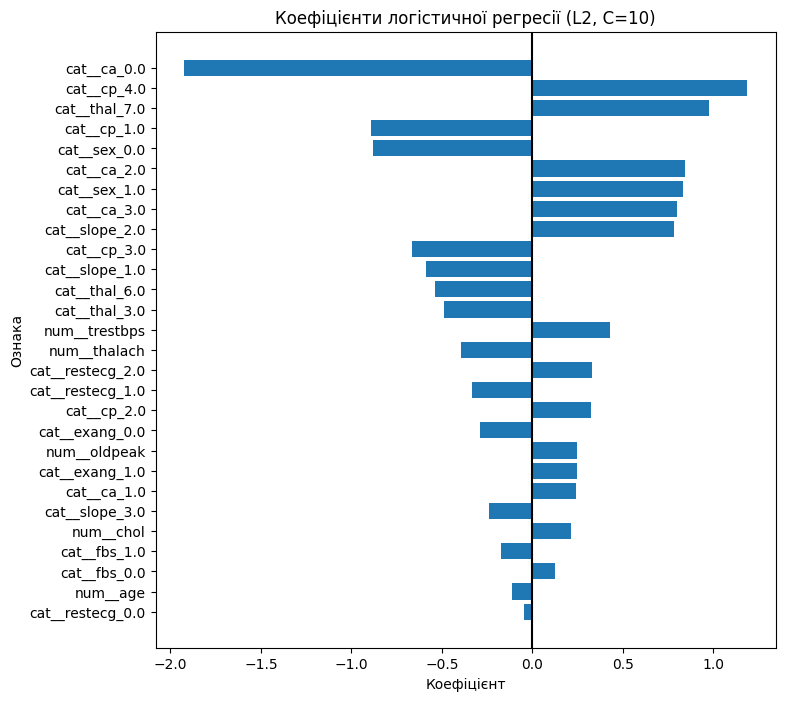

In [110]:
plt.figure(figsize=(8, 8))
coef_rev = coef_sorted.iloc[::-1]
plt.barh(coef_rev["feature"], coef_rev["coef"])
plt.axvline(0, color="black")
plt.xlabel("Коефіцієнт")
plt.ylabel("Ознака")
plt.title("Коефіцієнти логістичної регресії (L2, C=10)")
plt.show()

### Висновки з аналізу коефіцієнтів

**Загальна картина.** Із 28 коефіцієнтів найбільші за модулем належать категоріальним ознакам: перші 13 позицій займають one-hot-колонки, а перша числова ознака (`trestbps`, 0,4302) лише 14-та. Найслабші коефіцієнти мають `restecg = 0` (-0,0472) та `age` (-0,1122).

**Групи категоріальних ознак.**
- `ca` (кількість судин): `ca = 0` має найсильніший вплив у моделі (-1,9262), тобто відсутність помітних судин різко знижує оцінку ризику. Для `ca = 1, 2, 3` коефіцієнти додатні (0,2385; 0,8409; 0,8003), тобто більша кількість судин підвищує ризик.
- `cp` (тип болю в грудях): `cp = 4` підвищує ризик (1,1886), `cp = 2` трохи підвищує (0,3233), а `cp = 1` і `cp = 3` знижують (-0,8921 і -0,6662).
- `thal`: `thal = 7` підвищує ризик (0,9779), тоді як `thal = 3` і `thal = 6` знижують (-0,4883 і -0,5359).
- `slope`: `slope = 2` підвищує (0,7799), `slope = 1` і `slope = 3` знижують (-0,5885 і -0,2378).
- `restecg`: `restecg = 2` підвищує (0,3320), `restecg = 1` знижує (-0,3313), `restecg = 0` майже нейтральний (-0,0472).

**Бінарні ознаки.** Для `sex`, `exang` і `fbs` модель має по два коефіцієнти (для 0 та для 1), які майже дзеркальні (наприклад, `sex = 0` це -0,8802, а `sex = 1` це 0,8337). Реальний вплив такої ознаки показує різниця між ними: перехід від `sex = 0` до `sex = 1` змінює log-odds приблизно на 1,71, для `exang` на 0,54, для `fbs` на -0,30. Тому окремі коефіцієнти таких колонок не слід читати поодинці.

**Числові ознаки** (стандартизовані, тому порівнянні між собою): `trestbps` (0,4302) і `thalach` (-0,3921) впливають найбільше, далі `oldpeak` (0,2457), `chol` (0,2118) та `age` (-0,1122). Від'ємний знак у `age` не означає, що вік знижує ризик: коефіцієнт показує вплив за незмінних інших ознак (насамперед `thalach`), і він малий.

**Обмеження.** Коефіцієнти описують зв'язок у навчальних даних і не доводять причинно-наслідкового чи медичного впливу.